# Jupyter Notebook for Exploratory Data Analysis on Final StatsBomb Dataset


This notebook runs basic EDA on the player season dataset:

- Histogram of target variables  
- Scatterplots of xThreat vs output metrics  
- Correlation heatmap (reduced feature set)  
- Boxplots by position  
- All visuals are saved under `reports/figures/`


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

plt.style.use("default")
plt.rcParams["figure.figsize"] = (8, 5)

DATA_PATH = Path("../statsbomb_pipeline/data/processed/player_season_model_dataset.csv")
FIGURES_DIR = Path("reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)


In [16]:
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
df.head()

print("Dtypes:\n", df.dtypes, "\n")
print("Missing values:\n", df.isna().sum())


Shape: (558, 15)
Dtypes:
 player_id                 int64
player_name              object
team_id                   int64
team_name                object
minutes_played_total    float64
matches_played            int64
xThreat_total           float64
xThreat_pass_total      float64
xThreat_carry_total     float64
xg_total                float64
position                 object
minutes_90s             float64
xThreat_per90           float64
xThreat_pass_per90      float64
xThreat_carry_per90     float64
dtype: object 

Missing values:
 player_id               0
player_name             0
team_id                 0
team_name               0
minutes_played_total    0
matches_played          0
xThreat_total           0
xThreat_pass_total      0
xThreat_carry_total     0
xg_total                0
position                0
minutes_90s             0
xThreat_per90           0
xThreat_pass_per90      0
xThreat_carry_per90     0
dtype: int64


## Define core columns we care about

In [19]:
target_cols = [
    "xThreat_per90",
    "xThreat_total",
    "xg_total",
]

feature_cols = [
    "minutes_played_total",
    "matches_played",
    "xThreat_total",
    "xThreat_pass_total",
    "xThreat_carry_total",
    "xg_total",
    "xThreat_per90",
    "xThreat_pass_per90",
    "xThreat_carry_per90",
]


# Histogram of Target Variables

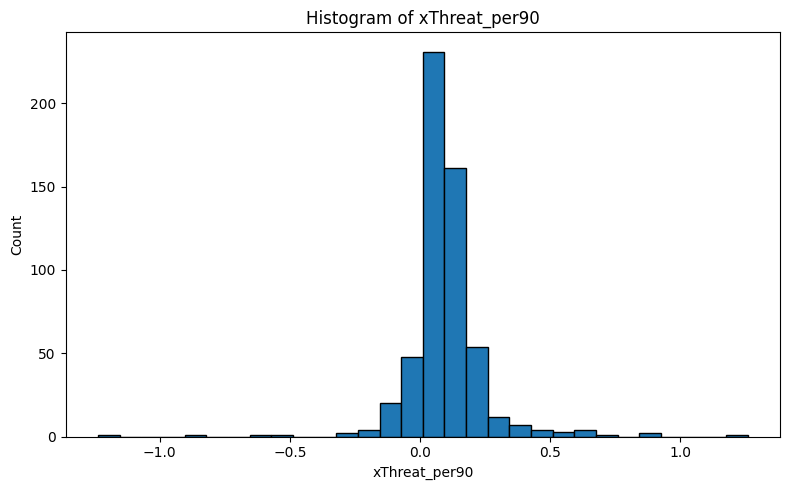

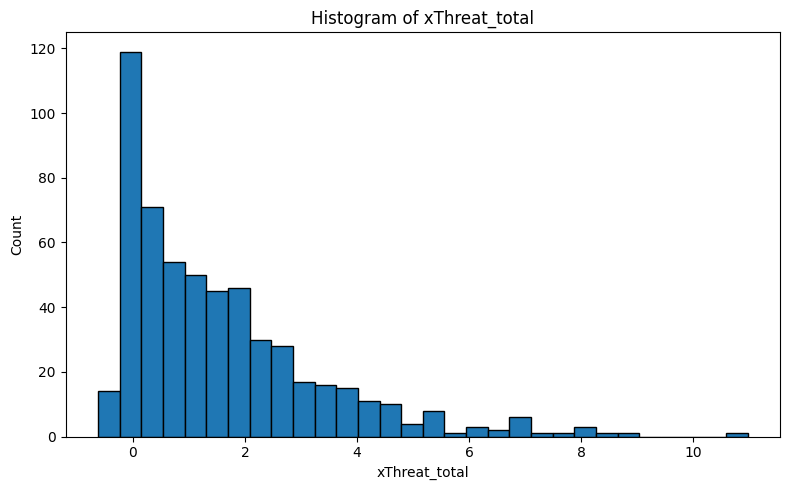

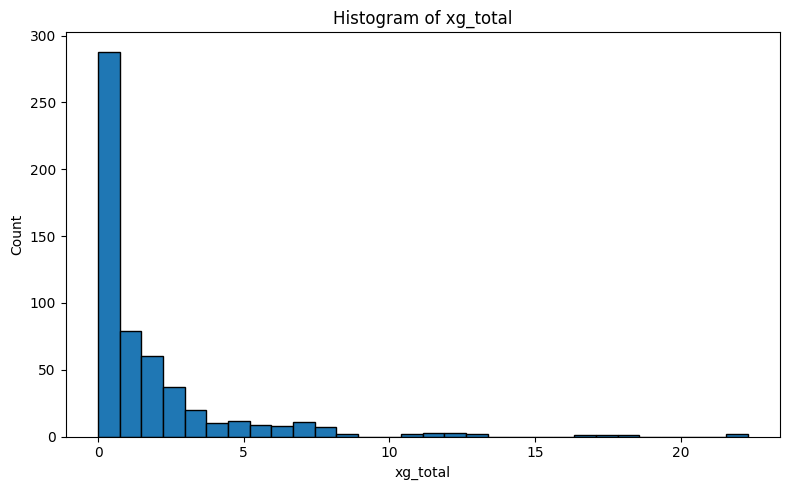

In [20]:
for col in target_cols:
    fig, ax = plt.subplots()
    ax.hist(df[col], bins=30, edgecolor="black")
    ax.set_title(f"Histogram of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")

    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"hist_{col}.png", dpi=300)
    plt.show()


## Scatterplots

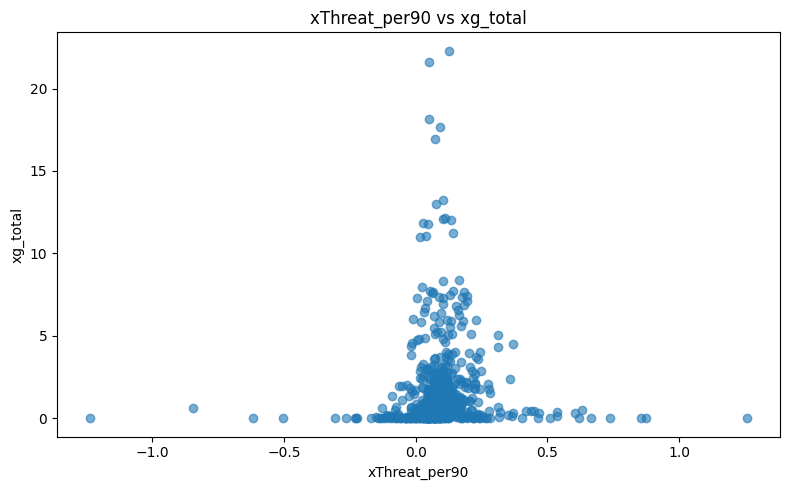

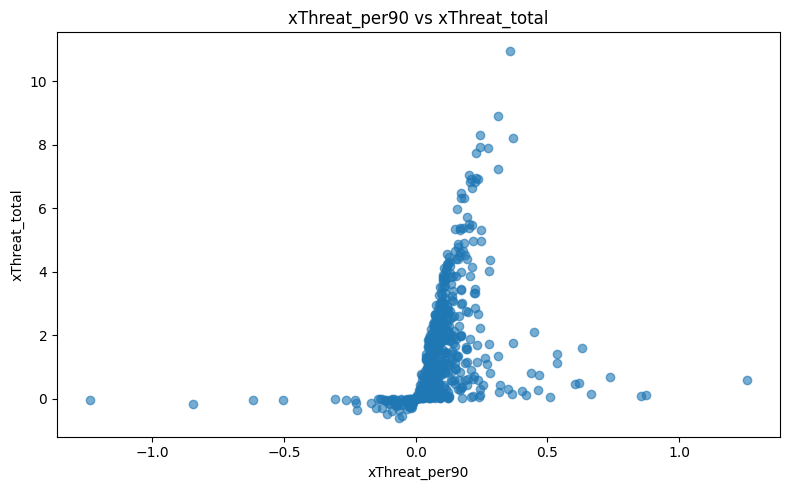

In [21]:
x_col = "xThreat_per90"
y_cols = ["xg_total", "xThreat_total"]

for y_col in y_cols:
    fig, ax = plt.subplots()
    ax.scatter(df[x_col], df[y_col], alpha=0.6)
    ax.set_title(f"{x_col} vs {y_col}")
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)

    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"scatter_{x_col}_vs_{y_col}.png", dpi=300)
    plt.show()


## Correlation Heat Map

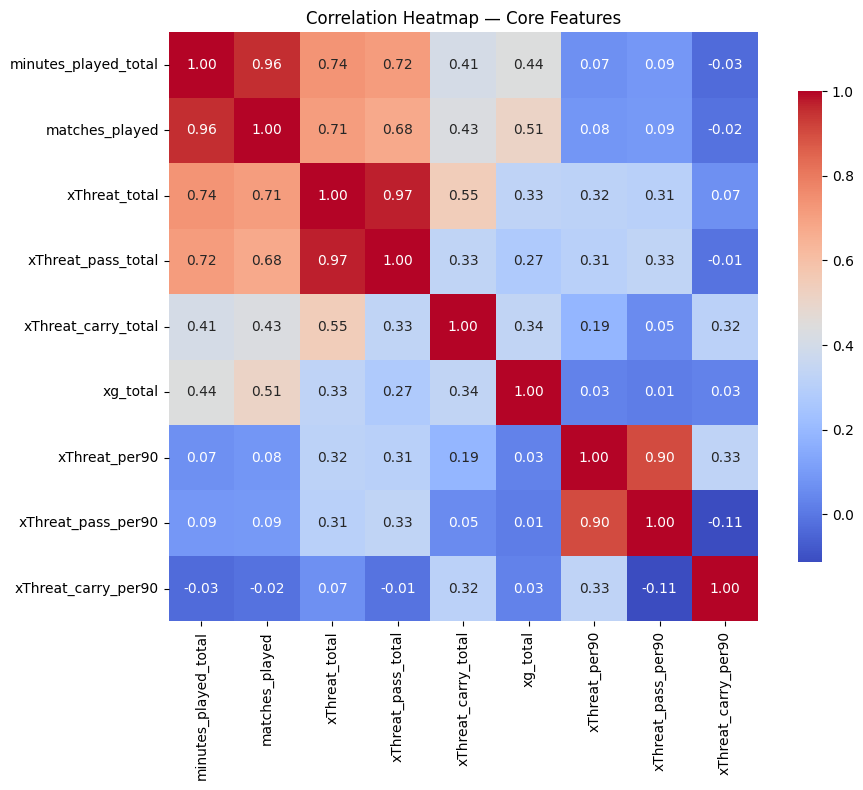

In [22]:
corr = df[feature_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr,
    ax=ax,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    cbar_kws={"shrink": 0.8},
)
ax.set_title("Correlation Heatmap — Core Features")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "corr_heatmap_core_features.png", dpi=300)
plt.show()


## Distribution of Minutes

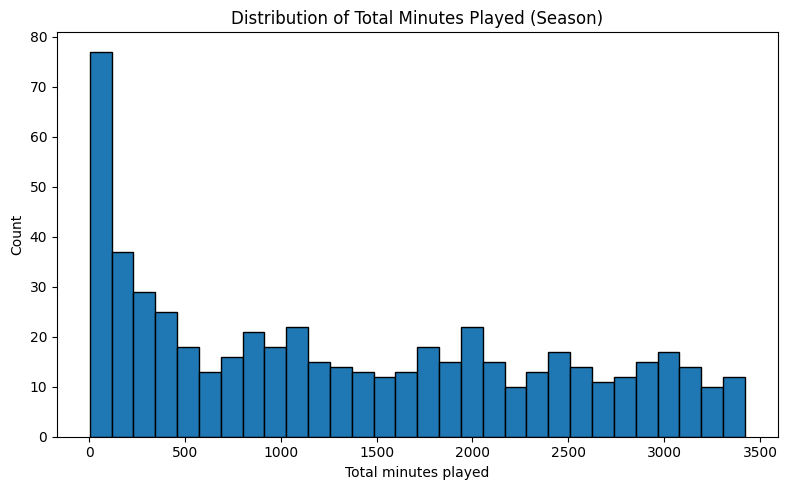

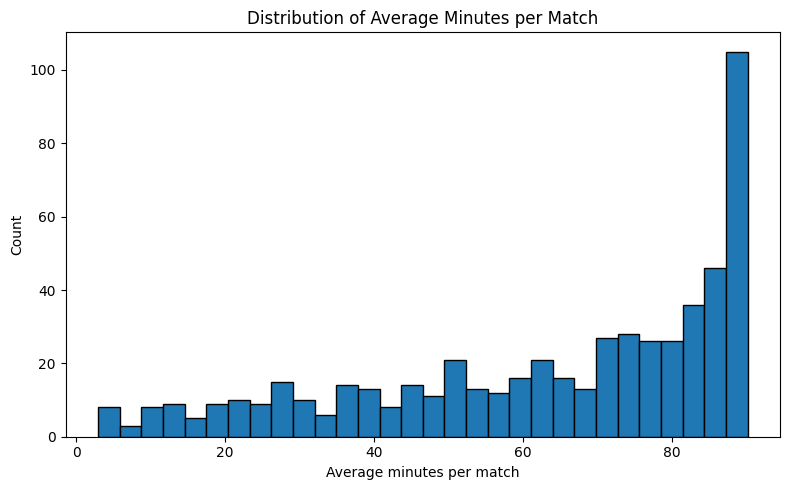

,minutes_played_total,matches_played,minutes_per_match
count,558.000000,558.000000,558.000000
mean,1349.001493,18.539427,63.545720
std,1058.614166,12.045145,24.648394
min,2.933333,1.000000,2.933333
25%,315.000000,7.000000,45.987431
50%,1159.033333,18.000000,71.188690
75%,2211.383333,29.750000,85.115589
max,3420.833333,38.000000,90.190741


In [26]:
fig, ax = plt.subplots()
ax.hist(df["minutes_played_total"], bins=30, edgecolor="black")
ax.set_title("Distribution of Total Minutes Played (Season)")
ax.set_xlabel("Total minutes played")
ax.set_ylabel("Count")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "hist_minutes_played_total.png", dpi=300)
plt.show()


df["minutes_per_match"] = df["minutes_played_total"] / df["matches_played"]

fig, ax = plt.subplots()
ax.hist(df["minutes_per_match"], bins=30, edgecolor="black")
ax.set_title("Distribution of Average Minutes per Match")
ax.set_xlabel("Average minutes per match")
ax.set_ylabel("Count")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "hist_minutes_per_match.png", dpi=300)
plt.show()

df[["minutes_played_total", "matches_played", "minutes_per_match"]].describe()



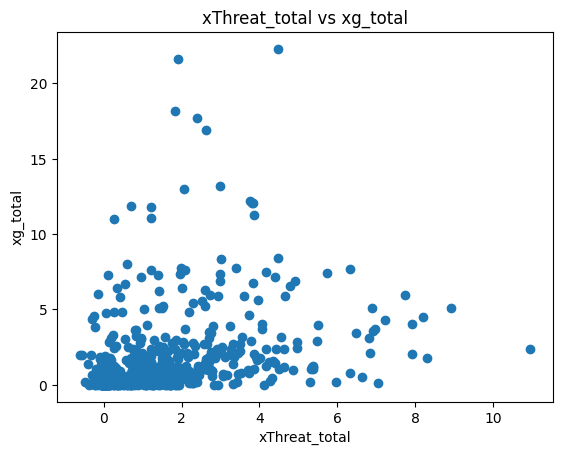

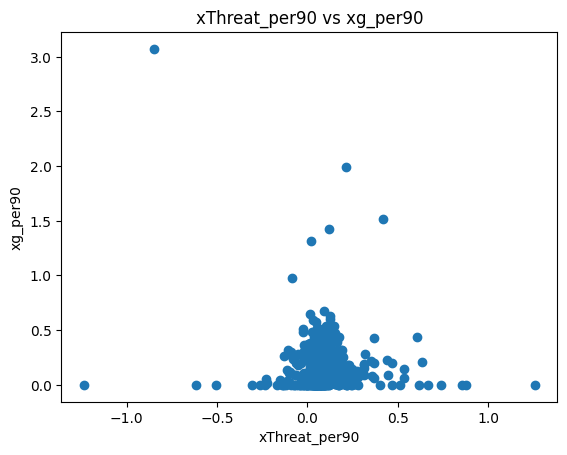

                      minutes_played_total  xThreat_total  xThreat_per90  \
minutes_played_total              1.000000       0.737863       0.068047   
xThreat_total                     0.737863       1.000000       0.321082   
xThreat_per90                     0.068047       0.321082       1.000000   
xg_total                          0.439771       0.328945       0.026766   
xg_per90                         -0.070117      -0.055113      -0.113956   

                      xg_total  xg_per90  
minutes_played_total  0.439771 -0.070117  
xThreat_total         0.328945 -0.055113  
xThreat_per90         0.026766 -0.113956  
xg_total              1.000000  0.404378  
xg_per90              0.404378  1.000000  


In [12]:
# xThreat vs xG totals
plt.scatter(df["xThreat_total"], df["xg_total"])
plt.xlabel("xThreat_total")
plt.ylabel("xg_total")
plt.title("xThreat_total vs xg_total")
plt.show()

# xThreat_per90 vs xg_total or xg_per90 (if you compute it)
df["xg_per90"] = df["xg_total"] / df["minutes_90s"]

plt.scatter(df["xThreat_per90"], df["xg_per90"])
plt.xlabel("xThreat_per90")
plt.ylabel("xg_per90")
plt.title("xThreat_per90 vs xg_per90")
plt.show()

# Quick correlations
corr_cols = ["minutes_played_total", "xThreat_total", "xThreat_per90", "xg_total", "xg_per90"]
print(df[corr_cols].corr())


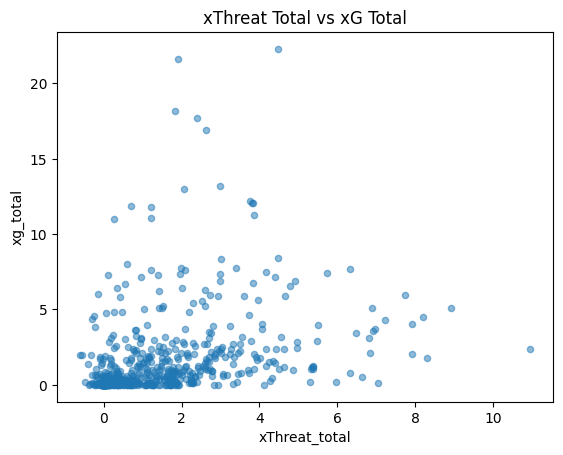

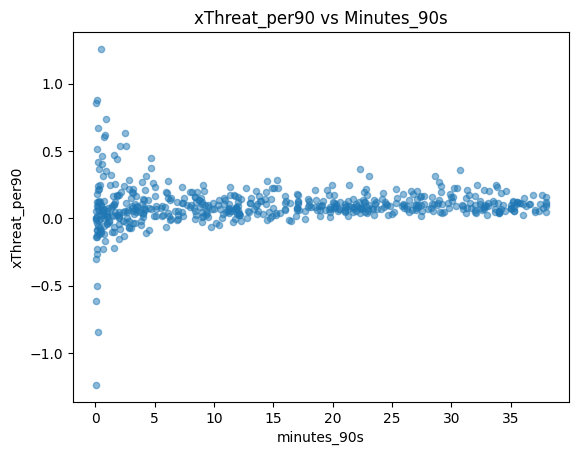

In [14]:
# xThreat vs xG season totals
df.plot.scatter(x="xThreat_total", y="xg_total", alpha=0.5)
plt.title("xThreat Total vs xG Total")
plt.show()

# xThreat_per90 vs minutes_90s to see small-sample madness
df.plot.scatter(x="minutes_90s", y="xThreat_per90", alpha=0.5)
plt.title("xThreat_per90 vs Minutes_90s")
plt.show()


## Final Conclusions


Data is looking great so far. Do need to do some additional cleaning in terms of removing players below the 500 minute mark and 1000 minute mark depending on which model I am running.
I can also standardize certain data in terms of the range and variance depending on the model in order to get better metrics. Still a very good solid amount of data to zone in and focus on.

xg_total is our target variable in this study